# Enterprise Customer Intelligence & Sales Analytics Platform
### A Unified Machine Learning Mini Project on a Single E-Commerce Dataset

This project implements an end-to-end business intelligence machine learning system using a **single source of truth dataset**: `data/customer_sales_analytics.csv`.

Across this single dataset, we solve four core business problems:
1. **Regression & Statistical Analysis**: Predict customer annual spend (`Total_Annual_Spend_USD`) using `LinearRegression`, evaluate with `mean_squared_error` and `math.sqrt(mse)` (RMSE), and compute SciPy correlation metrics ($r$, $p$-value).
2. **Supervised Multi-Model Classification**: Benchmark 5 classifiers (`LogisticRegression`, `DecisionTreeClassifier`, `KNeighborsClassifier`, `GaussianNB`, `SVC`) to predict `High_Value_Customer` (VIP vs. Standard) using `StandardScaler`, `confusion_matrix`, `precision_score`, `recall_score`, and `f1_score`.
3. **Unsupervised Clustering**: Segment customers into behavioral market personas using `KMeans` with the Elbow Method and 2D centroid visualization.
4. **Natural Language Processing & Model Persistence**: Automatically classify incoming text reviews (`Customer_Review`) into Positive vs. Negative sentiment using `TfidfVectorizer` and `MultinomialNB`, and serialize the complete pipeline with `joblib` for real-time inference.


## 1. Setup & Library Imports


In [1]:
import os
os.environ["MPLCONFIGDIR"] = "/tmp/matplotlib"

import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import joblib

# Scikit-Learn Preprocessing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler

# Scikit-Learn Models
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.svm import SVC
from sklearn.cluster import KMeans

# Feature Extraction & Metrics
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import (
    mean_squared_error,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    accuracy_score,
    classification_report
)

# Optional dataset loader for academic verification
from sklearn.datasets import load_breast_cancer

# Styling
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams.update({'figure.autolayout': True, 'font.size': 11})
print("✓ All libraries successfully loaded!")


✓ All libraries successfully loaded!


## 2. Single Dataset Ingestion & Tabular Inspection


In [2]:
# Load the single unified dataset
df = pd.read_csv('data/customer_sales_analytics.csv')

print(f"Dataset Dimensions: {df.shape[0]} rows × {df.shape[1]} columns")
print("\n--- Unified Dataset Preview (First 5 Rows) ---")
display(df.head(5))

print("\n--- Dataset Summary Statistics ---")
display(df.describe().round(2))


Dataset Dimensions: 500 rows × 13 columns

--- Unified Dataset Preview (First 5 Rows) ---


,Customer_ID,Age,Gender,Membership_Tier,Annual_Income_kUSD,Purchase_Frequency_Yearly,Avg_Order_Value_USD,App_Weekly_Hours,Discount_Usage_Pct,Total_Annual_Spend_USD,High_Value_Customer,Customer_Review,Feedback_Sentiment
0,CUST-1001,57,Male,Silver,95.2,21,99.28,1.5,4.3,2147.28,0,Faulty merchandise and frustrating return poli...,Negative
1,CUST-1002,47,Female,Silver,61.4,22,83.81,2.3,22.4,1916.47,0,The latest app update completely broke navigat...,Negative
2,CUST-1003,33,Male,Gold,101.2,24,132.29,0.7,7.6,3094.87,1,Outstanding value for money. Durable build qua...,Positive
3,CUST-1004,61,Male,Silver,86.2,16,110.32,6.6,10.2,1967.28,0,App keeps freezing and crashing whenever I try...,Negative
4,CUST-1005,26,Female,Bronze,68.7,13,79.71,6.0,6.9,1163.80,0,"Clean design, intuitive navigation, and reliab...",Positive



--- Dataset Summary Statistics ---


,Age,Annual_Income_kUSD,Purchase_Frequency_Yearly,Avg_Order_Value_USD,App_Weekly_Hours,Discount_Usage_Pct,Total_Annual_Spend_USD,High_Value_Customer
count,500.00,500.00,500.00,500.00,500.00,500.00,500.00,500.00
mean,43.68,67.67,19.15,87.55,4.30,14.08,1839.90,0.34
std,14.13,24.45,6.15,25.23,3.83,8.10,943.50,0.48
min,19.00,22.00,7.00,28.00,0.50,0.90,404.00,0.00
25%,32.00,50.80,15.00,70.25,1.50,8.28,1156.48,0.00
50%,44.00,68.15,18.00,84.13,3.00,12.40,1676.42,0.00
75%,55.00,85.02,23.00,104.12,5.90,19.23,2244.78,1.00
max,67.00,143.40,42.00,173.71,22.00,44.00,6565.54,1.00


## 3. Categorical Encoding (LabelEncoder) & Statistical Hypothesis Testing (SciPy & Math)


In [3]:
# Encode Membership Tier
le = LabelEncoder()
df['Membership_Tier_Code'] = le.fit_transform(df['Membership_Tier'])

tier_mapping = pd.DataFrame({
    'Original_Tier': le.classes_,
    'Encoded_Code': le.transform(le.classes_)
})
print("--- LabelEncoder Mapping Table ---")
display(tier_mapping)

# Analytical Statistics using SciPy and Math
income = df['Annual_Income_kUSD'].values
spend = df['Total_Annual_Spend_USD'].values

pearson_r, p_val = stats.pearsonr(income, spend)
mean_inc = float(np.mean(income))
std_inc = math.sqrt(sum((x - mean_inc)**2 for x in income) / (len(income) - 1))

print(f"• SciPy Pearson Correlation (Income vs Spend): r = {pearson_r:.4f} (p-value: {p_val:.2e})")
print(f"• Math-Calculated Income Mean: ${mean_inc:.2f}k, StdDev: ${std_inc:.2f}k")


--- LabelEncoder Mapping Table ---


,Original_Tier,Encoded_Code
0,Bronze,0
1,Gold,1
2,Platinum,2
3,Silver,3


• SciPy Pearson Correlation (Income vs Spend): r = 0.3172 (p-value: 3.80e-13)
• Math-Calculated Income Mean: $67.67k, StdDev: $24.45k


### Correlation Matrix & Heatmap


--- Feature Correlation Table ---


,Age,Membership_Tier_Code,Annual_Income_kUSD,Purchase_Frequency_Yearly,Avg_Order_Value_USD,App_Weekly_Hours,Discount_Usage_Pct,Total_Annual_Spend_USD
Age,1.000,-0.002,-0.084,0.023,-0.084,-0.029,-0.071,-0.032
Membership_Tier_Code,-0.002,1.000,0.015,0.292,0.143,0.019,0.025,0.255
Annual_Income_kUSD,-0.084,0.015,1.000,-0.070,0.648,-0.018,0.011,0.317
Purchase_Frequency_Yearly,0.023,0.292,-0.070,1.000,0.295,-0.061,0.049,0.800
Avg_Order_Value_USD,-0.084,0.143,0.648,0.295,1.000,-0.040,0.003,0.770
App_Weekly_Hours,-0.029,0.019,-0.018,-0.061,-0.040,1.000,-0.040,0.014
Discount_Usage_Pct,-0.071,0.025,0.011,0.049,0.003,-0.040,1.000,-0.025
Total_Annual_Spend_USD,-0.032,0.255,0.317,0.800,0.770,0.014,-0.025,1.000


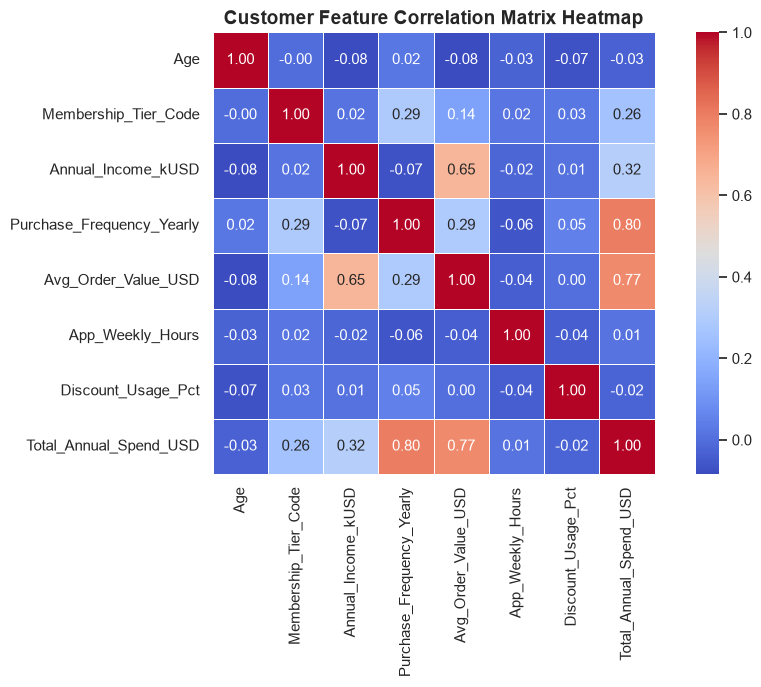

In [4]:
num_cols = [
    'Age', 'Membership_Tier_Code', 'Annual_Income_kUSD',
    'Purchase_Frequency_Yearly', 'Avg_Order_Value_USD',
    'App_Weekly_Hours', 'Discount_Usage_Pct', 'Total_Annual_Spend_USD'
]
corr_matrix = df[num_cols].corr()

print("--- Feature Correlation Table ---")
display(corr_matrix.round(3))

plt.figure(figsize=(9.5, 7))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", square=True, linewidths=0.5)
plt.title("Customer Feature Correlation Matrix Heatmap", fontsize=14, weight='bold')
plt.show()


## 4. Linear Regression: Predicting Annual Customer Spend


--- Linear Regression Test Set Predictions Table ---


,Actual Spend ($),Predicted Spend ($),Residual ($),Abs % Error
0,1475.16,1341.19,133.97,9.08
1,674.30,398.07,276.23,40.97
2,2084.29,2171.73,-87.44,4.20
3,2253.70,2364.78,-111.08,4.93
4,607.91,417.31,190.60,31.35
5,973.53,770.60,202.93,20.85
6,3638.14,3413.41,224.73,6.18


• Model MSE:  38849.88
• Model RMSE: $197.10 (calculated via math.sqrt)
• Model R²:   0.9639


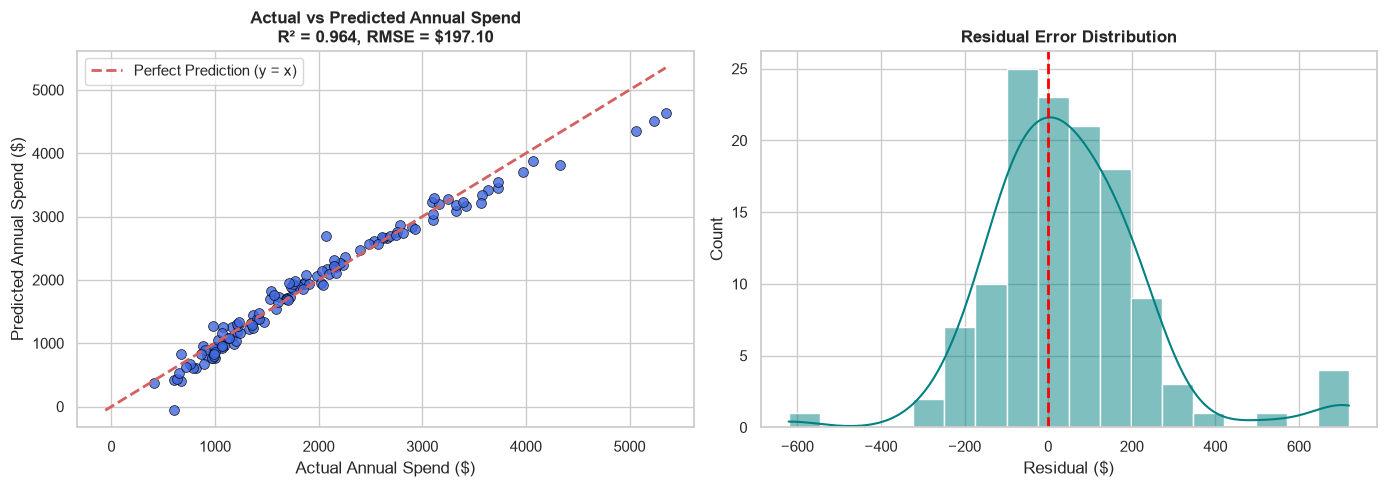

In [5]:
feature_cols = [
    'Age', 'Membership_Tier_Code', 'Annual_Income_kUSD',
    'Purchase_Frequency_Yearly', 'Avg_Order_Value_USD',
    'App_Weekly_Hours', 'Discount_Usage_Pct'
]
X = df[feature_cols]
y = df['Total_Annual_Spend_USD']

# Split data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)

# Standardize features
scaler_reg = StandardScaler()
X_train_scaled = scaler_reg.fit_transform(X_train)
X_test_scaled = scaler_reg.transform(X_test)

# Train model
reg_model = LinearRegression()
reg_model.fit(X_train_scaled, y_train)

# Predict & Evaluate
y_pred = reg_model.predict(X_test_scaled)
mse = mean_squared_error(y_test, y_pred)
rmse = math.sqrt(mse)  # Computed via math module
r2 = reg_model.score(X_test_scaled, y_test)

# Prediction comparison table
pred_df = pd.DataFrame({
    'Actual Spend ($)': y_test.values.round(2),
    'Predicted Spend ($)': y_pred.round(2),
    'Residual ($)': (y_test.values - y_pred).round(2),
    'Abs % Error': (np.abs(y_test.values - y_pred) / y_test.values * 100).round(2)
})
print("--- Linear Regression Test Set Predictions Table ---")
display(pred_df.head(7))

print(f"• Model MSE:  {mse:.2f}")
print(f"• Model RMSE: ${rmse:.2f} (calculated via math.sqrt)")
print(f"• Model R²:   {r2:.4f}")

# Visualizations: Fit Scatter & Residual Histogram
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.scatterplot(x=y_test, y=y_pred, ax=axes[0], color='royalblue', alpha=0.8, edgecolor='black', s=50)
min_v, max_v = min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())
axes[0].plot([min_v, max_v], [min_v, max_v], 'r--', lw=2, label="Perfect Prediction (y = x)")
axes[0].set_title(f"Actual vs Predicted Annual Spend\nR² = {r2:.3f}, RMSE = ${rmse:.2f}", fontsize=12, weight='bold')
axes[0].set_xlabel("Actual Annual Spend ($)")
axes[0].set_ylabel("Predicted Annual Spend ($)")
axes[0].legend()

residuals = y_test - y_pred
sns.histplot(residuals, kde=True, ax=axes[1], color='teal', bins=18)
axes[1].axvline(0, color='red', linestyle='--', lw=2)
axes[1].set_title("Residual Error Distribution", fontsize=12, weight='bold')
axes[1].set_xlabel("Residual ($)")
plt.show()


## 5. Supervised Multi-Model Classification: Predicting VIP Customers
We benchmark 5 distinct classification algorithms on the single dataset to predict `High_Value_Customer`:
1. `LogisticRegression`
2. `DecisionTreeClassifier`
3. `KNeighborsClassifier`
4. `GaussianNB`
5. `SVC`


In [6]:
y_clf = df['High_Value_Customer']
X_clf = df[feature_cols]

X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
    X_clf, y_clf, test_size=0.25, random_state=42, stratify=y_clf
)

scaler_c = StandardScaler()
X_train_c_scaled = scaler_c.fit_transform(X_train_c)
X_test_c_scaled = scaler_c.transform(X_test_c)

models = {
    "Logistic Regression": LogisticRegression(random_state=42, max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(random_state=42, max_depth=5),
    "K-Nearest Neighbors": KNeighborsClassifier(n_neighbors=5),
    "Gaussian Naive Bayes": GaussianNB(),
    "Support Vector Machine (SVC)": SVC(kernel='rbf', random_state=42)
}

benchmark_records = []
cms = {}

for name, clf in models.items():
    clf.fit(X_train_c_scaled, y_train_c)
    preds = clf.predict(X_test_c_scaled)
    
    acc = accuracy_score(y_test_c, preds)
    prec = precision_score(y_test_c, preds)
    rec = recall_score(y_test_c, preds)
    f1 = f1_score(y_test_c, preds)
    cm = confusion_matrix(y_test_c, preds)
    
    cms[name] = cm
    benchmark_records.append({
        "Model Name": name,
        "Accuracy": acc,
        "Precision": prec,
        "Recall": rec,
        "F1-Score": f1
    })

benchmark_df = pd.DataFrame(benchmark_records)
benchmark_formatted = benchmark_df.copy()
for col in ["Accuracy", "Precision", "Recall", "F1-Score"]:
    benchmark_formatted[col] = (benchmark_formatted[col] * 100).round(2).astype(str) + "%"

print("--- 5-Classifier Performance Benchmark Table ---")
display(benchmark_formatted)


--- 5-Classifier Performance Benchmark Table ---


,Model Name,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,94.4%,92.86%,90.7%,91.76%
1,Decision Tree,92.8%,90.48%,88.37%,89.41%
2,K-Nearest Neighbors,93.6%,94.87%,86.05%,90.24%
3,Gaussian Naive Bayes,94.4%,97.37%,86.05%,91.36%
4,Support Vector Machine (SVC),96.0%,97.5%,90.7%,93.98%


### Classification Charts: Benchmark Bar Chart & Confusion Matrices


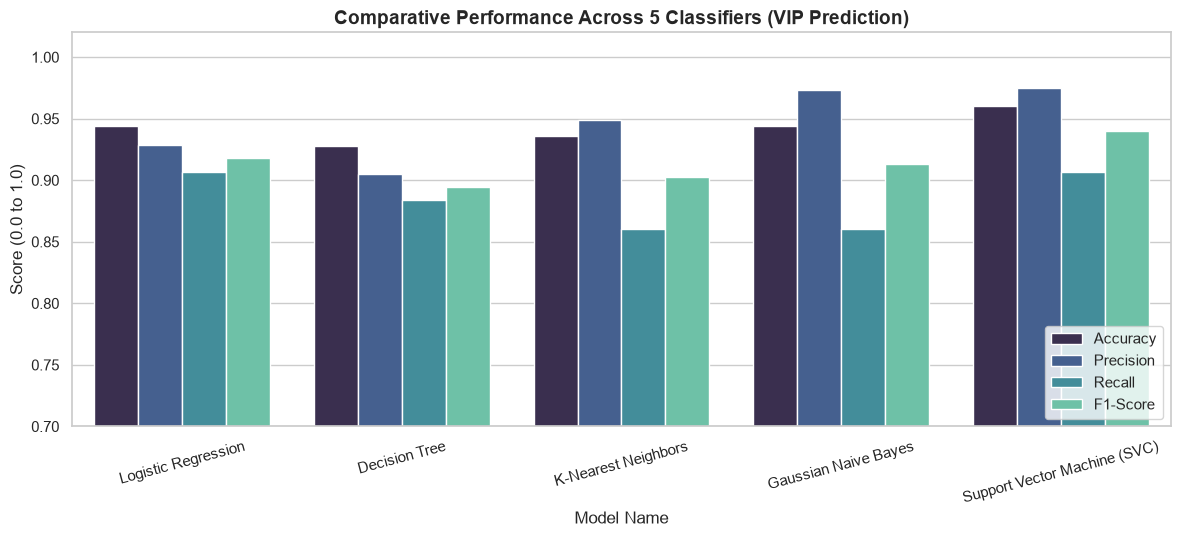

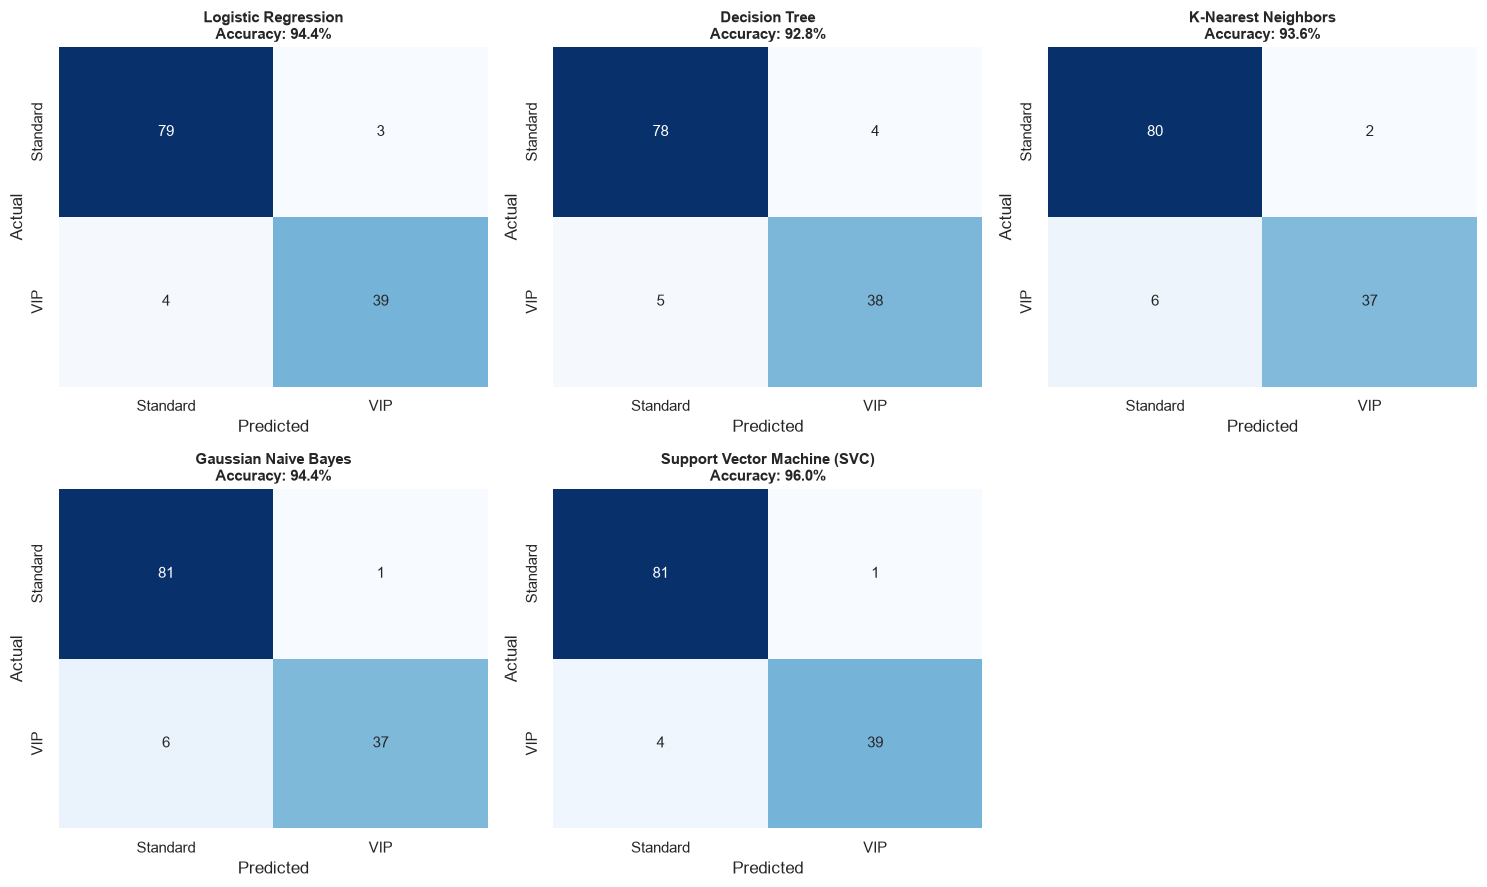

In [7]:
# Plot 1: Performance Bar Chart
melted_df = benchmark_df.melt(id_vars="Model Name", var_name="Metric", value_name="Score")
plt.figure(figsize=(12, 5.5))
sns.barplot(data=melted_df, x="Model Name", y="Score", hue="Metric", palette="mako")
plt.title("Comparative Performance Across 5 Classifiers (VIP Prediction)", fontsize=14, weight='bold')
plt.ylabel("Score (0.0 to 1.0)")
plt.ylim(0.70, 1.02)
plt.xticks(rotation=15)
plt.legend(loc='lower right')
plt.show()

# Plot 2: Confusion Matrices Grid
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.flatten()

for idx, (name, cm) in enumerate(cms.items()):
    ax = axes[idx]
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax,
                xticklabels=['Standard', 'VIP'],
                yticklabels=['Standard', 'VIP'])
    acc_val = benchmark_df.loc[benchmark_df['Model Name']==name, 'Accuracy'].values[0]
    ax.set_title(f"{name}\nAccuracy: {acc_val*100:.1f}%", fontsize=11, weight='bold')
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

axes[5].axis('off')
plt.show()


## 6. Unsupervised Learning: K-Means Customer Persona Segmentation


--- K-Means Customer Personas Summary Table ---


,Cluster_ID,Customer_Count,Avg_Income_kUSD,Avg_Spend_USD,Min_Spend_USD,Max_Spend_USD,Avg_Purchases
0,0,97,80.46,3364.67,2486.81,6565.54,26.76
1,1,199,84.62,1540.42,436.73,2475.62,16.13
2,2,204,45.04,1407.02,404.00,2778.81,18.49


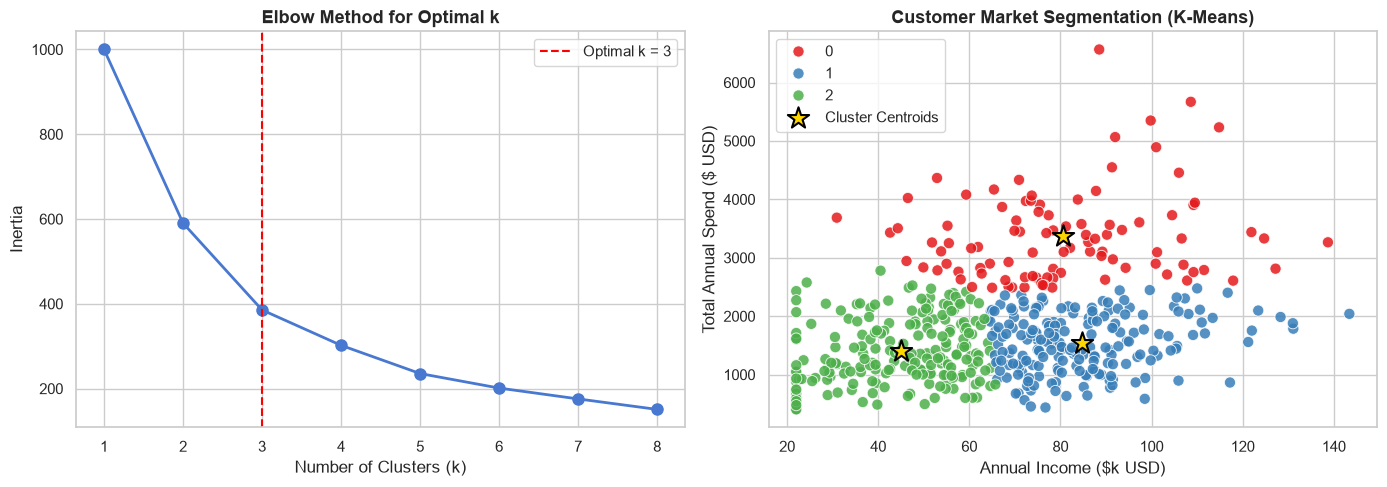

In [8]:
X_cluster = df[['Annual_Income_kUSD', 'Total_Annual_Spend_USD']]
scaler_cluster = StandardScaler()
X_cluster_scaled = scaler_cluster.fit_transform(X_cluster)

# Elbow Method
k_range = range(1, 9)
inertias = []
for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_cluster_scaled)
    inertias.append(km.inertia_)

# Fit Optimal k = 3
kmeans_opt = KMeans(n_clusters=3, random_state=42, n_init=10)
df['Cluster_ID'] = kmeans_opt.fit_predict(X_cluster_scaled)
centers = scaler_cluster.inverse_transform(kmeans_opt.cluster_centers_)

# Summary Table
persona_summary = df.groupby('Cluster_ID').agg(
    Customer_Count=('Customer_ID', 'count'),
    Avg_Income_kUSD=('Annual_Income_kUSD', 'mean'),
    Avg_Spend_USD=('Total_Annual_Spend_USD', 'mean'),
    Min_Spend_USD=('Total_Annual_Spend_USD', 'min'),
    Max_Spend_USD=('Total_Annual_Spend_USD', 'max'),
    Avg_Purchases=('Purchase_Frequency_Yearly', 'mean')
).round(2).reset_index()

print("--- K-Means Customer Personas Summary Table ---")
display(persona_summary)

# Visualizations: Elbow Curve & Clustered Scatter Plot
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(k_range, inertias, 'bo-', linewidth=2, markersize=8)
axes[0].axvline(x=3, color='red', linestyle='--', label='Optimal k = 3')
axes[0].set_title("Elbow Method for Optimal k", fontsize=13, weight='bold')
axes[0].set_xlabel("Number of Clusters (k)")
axes[0].set_ylabel("Inertia")
axes[0].legend()

sns.scatterplot(
    data=df, x='Annual_Income_kUSD', y='Total_Annual_Spend_USD',
    hue='Cluster_ID', palette='Set1', alpha=0.85, s=65, ax=axes[1]
)
axes[1].scatter(
    centers[:, 0], centers[:, 1],
    s=260, c='gold', marker='*', edgecolors='black', linewidths=1.5,
    label='Cluster Centroids', zorder=10
)
axes[1].set_title("Customer Market Segmentation (K-Means)", fontsize=13, weight='bold')
axes[1].set_xlabel("Annual Income ($k USD)")
axes[1].set_ylabel("Total Annual Spend ($ USD)")
axes[1].legend()
plt.show()


## 7. NLP Text Analytics: Customer Sentiment Classification & Joblib Model Persistence


• MultinomialNB Sentiment Accuracy: 92.00%

--- Classification Report ---
              precision    recall  f1-score   support

    Negative       0.83      1.00      0.91        50
    Positive       1.00      0.87      0.93        75

    accuracy                           0.92       125
   macro avg       0.92      0.93      0.92       125
weighted avg       0.93      0.92      0.92       125



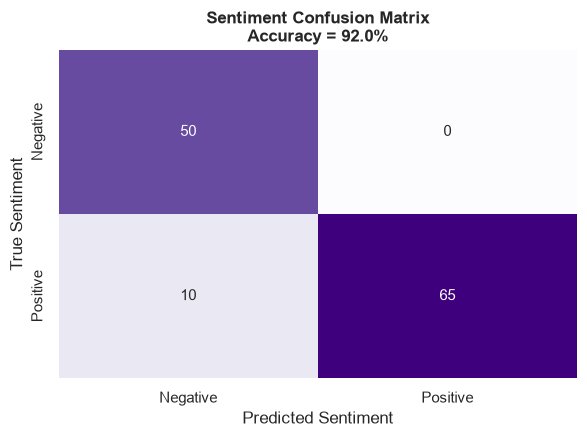

✓ Pipeline saved to disk at 'models/sentiment_pipeline.joblib'

--- Real-Time Live Inference with Saved Joblib Model ---


,Incoming Customer Review,Automated Sentiment Classification
0,Incredible shopping experience! Checkout was f...,Positive
1,"Terrible experience. Package arrived late, bro...",Negative


In [9]:
# Train-test split on text reviews from the single dataset
X_train_txt, X_test_txt, y_train_txt, y_test_txt = train_test_split(
    df['Customer_Review'], df['Feedback_Sentiment'], test_size=0.25, random_state=42, stratify=df['Feedback_Sentiment']
)

# TF-IDF Feature Extraction
tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_features=300)
X_train_vec = tfidf.fit_transform(X_train_txt)
X_test_vec = tfidf.transform(X_test_txt)

# MultinomialNB Model
mnb = MultinomialNB(alpha=0.1)
mnb.fit(X_train_vec, y_train_txt)

# Predict & Evaluate
y_pred_txt = mnb.predict(X_test_vec)
nlp_acc = accuracy_score(y_test_txt, y_pred_txt)
print(f"• MultinomialNB Sentiment Accuracy: {nlp_acc * 100:.2f}%\n")
print("--- Classification Report ---")
print(classification_report(y_test_txt, y_pred_txt))

# Confusion Matrix Chart
plt.figure(figsize=(6, 4.5))
cm_nlp = confusion_matrix(y_test_txt, y_pred_txt, labels=['Negative', 'Positive'])
sns.heatmap(cm_nlp, annot=True, fmt='d', cmap='Purples', cbar=False,
            xticklabels=['Negative', 'Positive'], yticklabels=['Negative', 'Positive'])
plt.title(f"Sentiment Confusion Matrix\nAccuracy = {nlp_acc*100:.1f}%", fontsize=12, weight='bold')
plt.xlabel("Predicted Sentiment")
plt.ylabel("True Sentiment")
plt.show()

# Model Persistence with Joblib
pipeline_dict = {'vectorizer': tfidf, 'model': mnb}
os.makedirs('models', exist_ok=True)
joblib.dump(pipeline_dict, 'models/sentiment_pipeline.joblib')
print("✓ Pipeline saved to disk at 'models/sentiment_pipeline.joblib'")

# Reload Pipeline and Perform Live Real-Time Inferences
loaded_pipeline = joblib.load('models/sentiment_pipeline.joblib')

incoming_feedback = [
    "Incredible shopping experience! Checkout was fast and delivery arrived within 24 hours.",
    "Terrible experience. Package arrived late, broken merchandise and support was unhelpful."
]
test_vectors = loaded_pipeline['vectorizer'].transform(incoming_feedback)
live_predictions = loaded_pipeline['model'].predict(test_vectors)

live_df = pd.DataFrame({
    'Incoming Customer Review': incoming_feedback,
    'Automated Sentiment Classification': live_predictions
})
print("\n--- Real-Time Live Inference with Saved Joblib Model ---")
display(live_df)
